# Machine Learning Capstone Project: Heart Disease

**Tasks:** Regression, classification, and clustering  
**Dataset:** UCI Heart Disease — processed Cleveland subset  
**Level:** Beginner-friendly / university capstone

## Project goals
1. Predict a patient's age with Linear Regression using other available attributes. This is a demonstration regression task, not a medical use case.
2. Classify whether heart disease is present using Logistic Regression.
3. Explore feature-based groups using K-Means without using the disease label as a clustering input.

> **Important:** This educational dataset is small and historical. The models are not medical devices and must not be used for diagnosis or treatment. Run all cells from top to bottom. Metrics and plots are generated from the data at runtime rather than fabricated in advance.

## 1. Install/import libraries

In Google Colab, most libraries are already available. If running locally, install the packages listed in `README.md`.

In [1]:
# Uncomment the next line in a fresh environment if needed:
# %pip install pandas numpy scikit-learn matplotlib seaborn jupyter

from pathlib import Path
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_squared_error, r2_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, classification_report,
    silhouette_score
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
# Work whether Jupyter starts in the repository root or inside notebooks/.
if Path("notebooks").exists() and Path("README.md").exists():
    PROJECT_DIR = Path(".")
elif Path("../data").exists() and Path("../README.md").exists():
    PROJECT_DIR = Path("..")
else:
    # Google Colab or another standalone notebook session.
    PROJECT_DIR = Path(".")
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

## 2. Load the dataset

The UCI processed Cleveland file contains 303 records and 14 columns (13 input attributes plus a diagnosis field). In the raw file, `?` marks unknown values. The code first checks for a local copy and downloads it if it is not present. Internet access is needed only for the first download.

In [2]:
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]
local_csv = DATA_DIR / "processed.cleveland.data"
source_url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)

if local_csv.exists():
    raw = pd.read_csv(local_csv, header=None, names=columns, na_values="?")
else:
    try:
        raw = pd.read_csv(source_url, header=None, names=columns, na_values="?")
        raw.to_csv(local_csv, index=False, header=False)
        print(f"Downloaded and saved dataset to: {local_csv}")
    except Exception as exc:
        raise RuntimeError(
            "Could not download the UCI dataset. Download processed.cleveland.data "
            "from the UCI Heart Disease repository, place it in data/, and rerun."
        ) from exc

df = raw.copy()
# Convert all fields to numeric; invalid markers become NaN.
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Binary target: 0 means no disease; values 1-4 mean disease present.
df["target"] = (df["num"] > 0).astype("Int64")
df = df.drop(columns=["num"])
print("Dataset loaded successfully.")
display(df.head())

Dataset loaded successfully.


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 3. Data understanding

The raw source's `num` diagnosis is ordinal from 0 to 4. For classification, this project follows the common binary formulation: `0` = no disease and `1` = disease present (original values 1–4). The synthetic regression target is `age`.

In [3]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum().sort_values(ascending=False))
print("\nStatistical description:\n")
display(df.describe(include="all").T)
print("\nDuplicate rows:", df.duplicated().sum())

Shape: (303, 14)

Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types:
 age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        Int64
dtype: object

Missing values:
 ca          4
thal        2
cp          0
trestbps    0
age         0
sex         0
fbs         0
chol        0
restecg     0
thalach     0
oldpeak     0
exang       0
slope       0
target      0
dtype: int64

Statistical description:



,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2



Duplicate rows: 0


### Column guide

- `age`: age in years.
- `sex`: sex code in the original dataset (1 = male, 0 = female).
- `cp`: chest-pain type code.
- `trestbps`: resting blood pressure (mm Hg).
- `chol`: serum cholesterol (mg/dL).
- `fbs`: fasting blood sugar above 120 mg/dL (1 = yes, 0 = no).
- `restecg`: resting electrocardiographic result code.
- `thalach`: maximum heart rate achieved.
- `exang`: exercise-induced angina (1 = yes, 0 = no).
- `oldpeak`: ST depression induced by exercise relative to rest.
- `slope`: slope of the peak exercise ST segment (coded category).
- `ca`: number of major vessels visualized by fluoroscopy (0–3).
- `thal`: thalassemia test code in the original dataset.
- `target`: binary target derived from original `num`; 1 means disease present, 0 means absent.

Several codes represent categories even though they are stored as numbers. We encode categorical variables explicitly for model pipelines.

## 4. Exploratory Data Analysis (EDA)

The plots below help inspect distributions, possible outliers, target balance, and linear relationships. Correlation shows association, not causation.

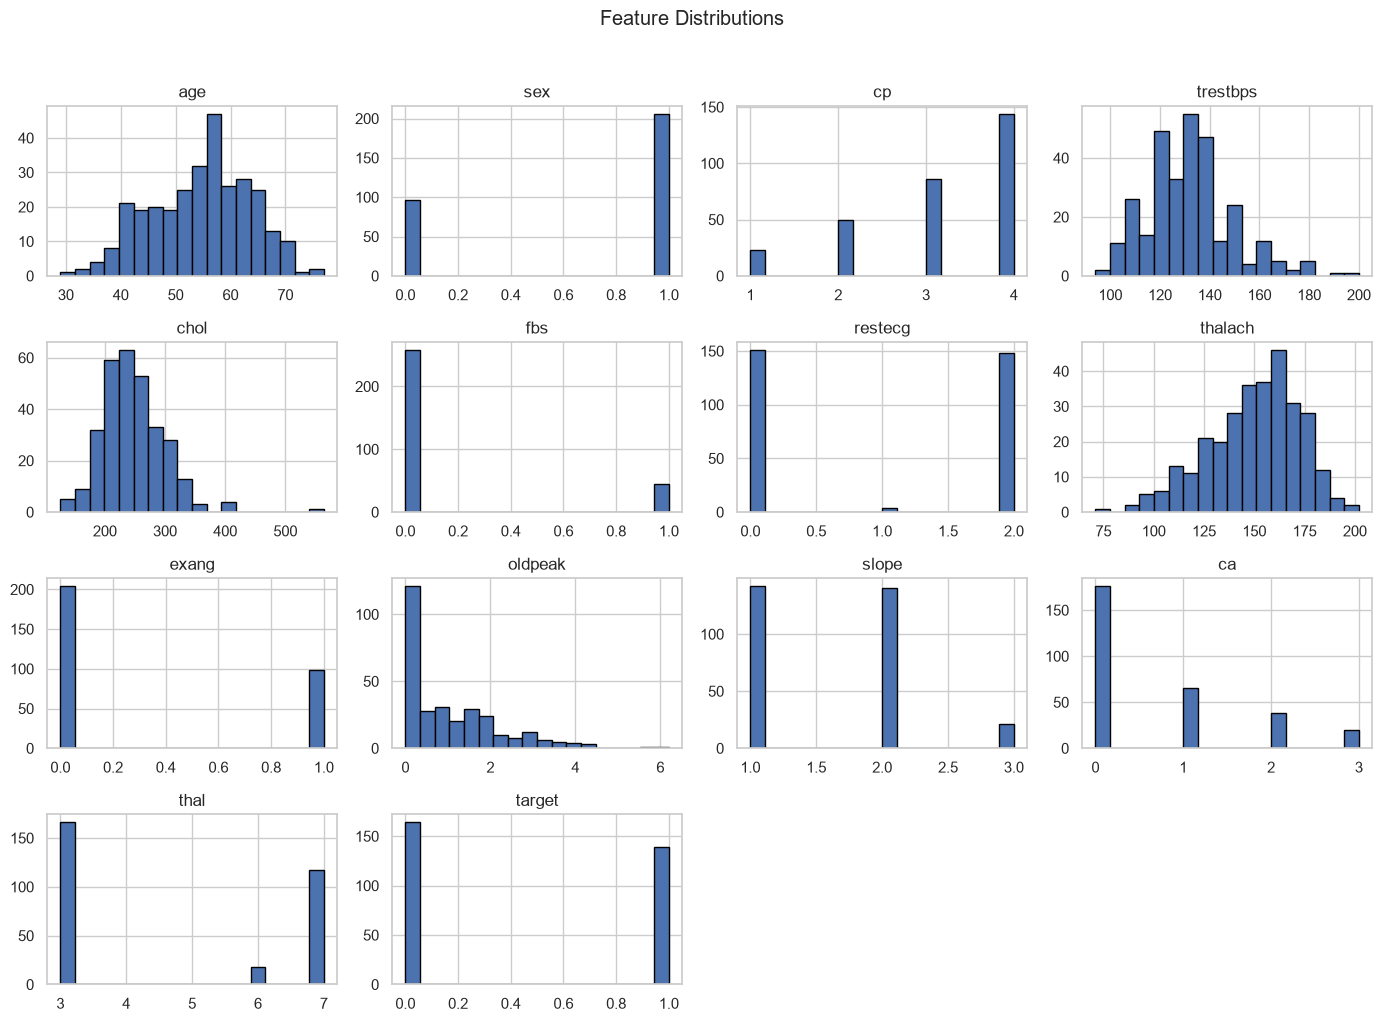

In [4]:
# Histogram grid for numeric variables
df.hist(figsize=(14, 10), bins=18, edgecolor="black")
plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "feature_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

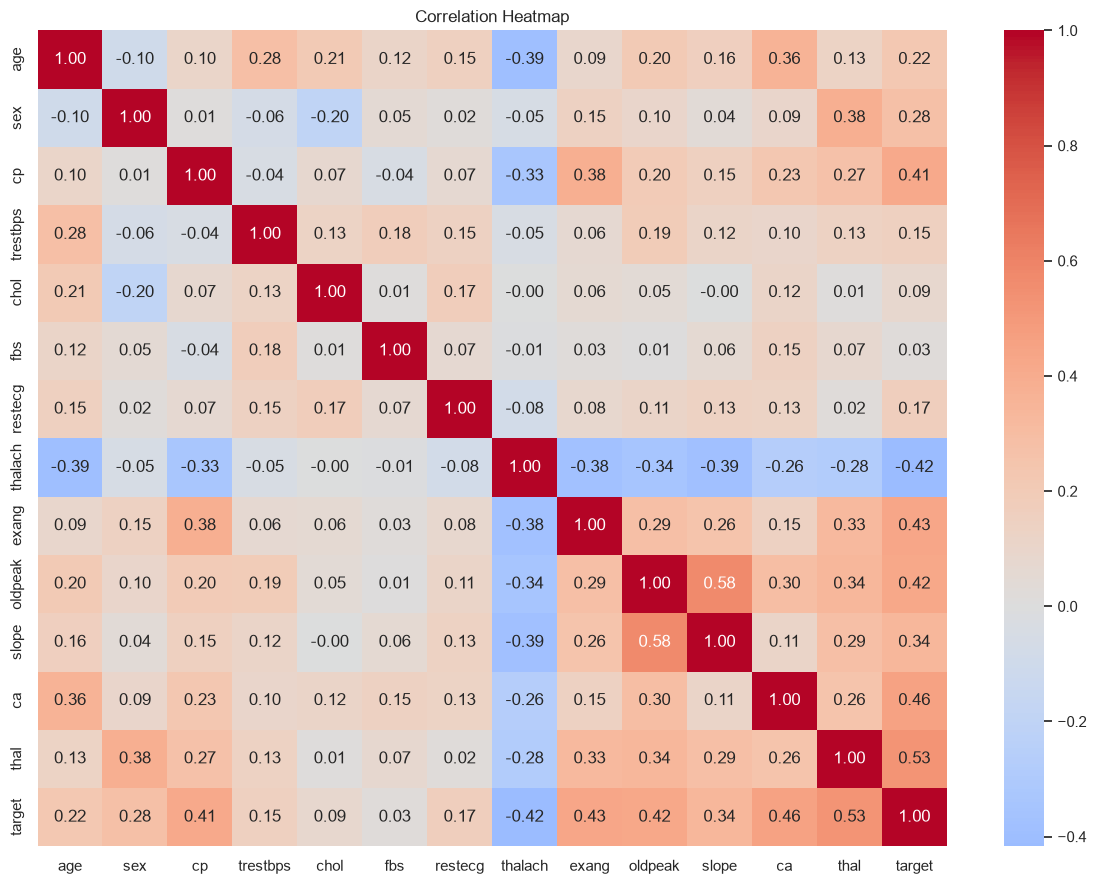

In [5]:
# Correlation heatmap (numerically coded categories are included only as a rough overview)
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

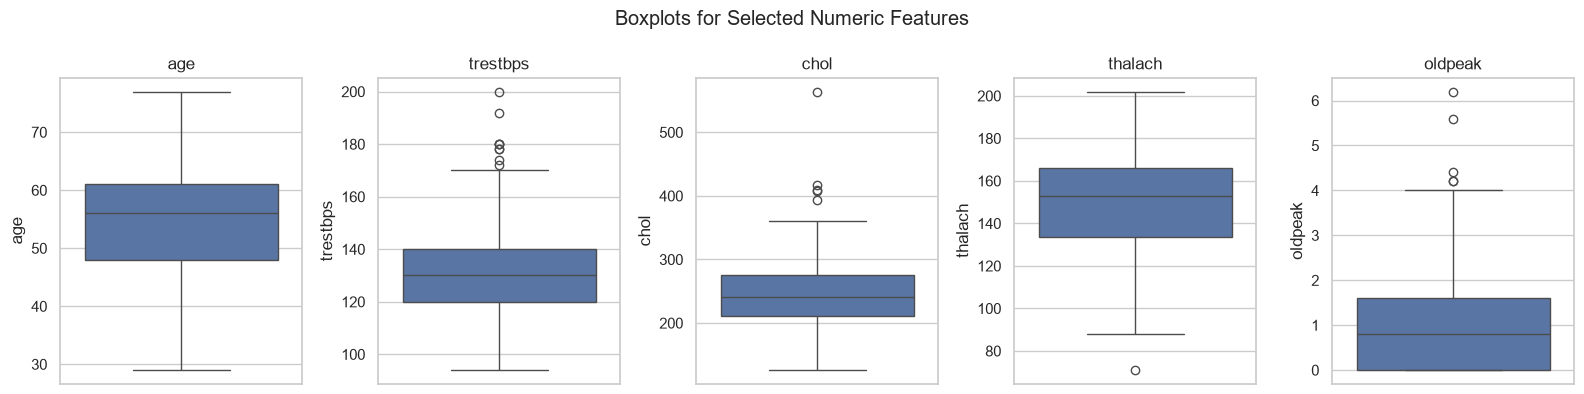

In [6]:
numeric_for_box = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(1, len(numeric_for_box), figsize=(16, 4))
for ax, col in zip(axes, numeric_for_box):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Boxplots for Selected Numeric Features")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

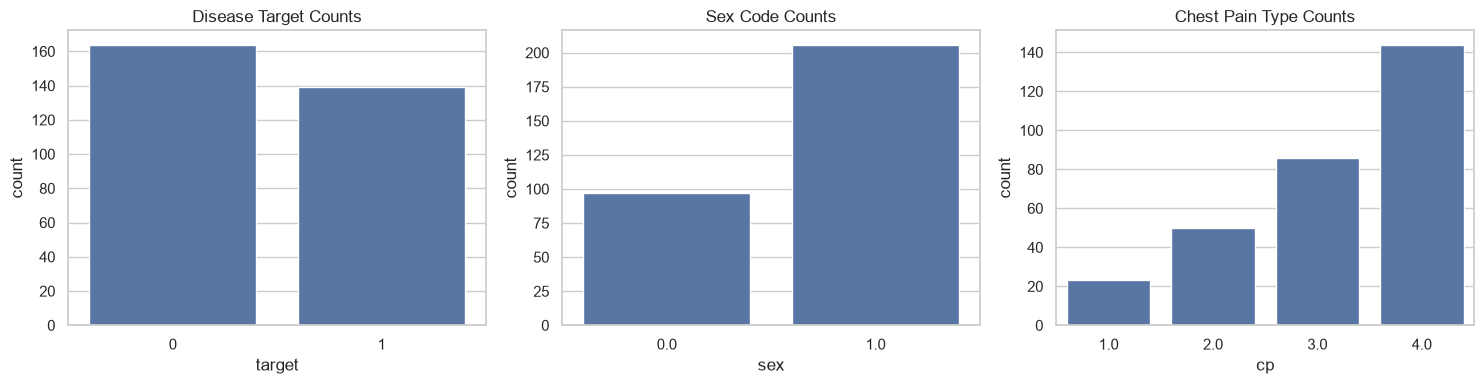

Target proportions:


,proportion
target,
0,0.541254
1,0.458746


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x="target", ax=axes[0])
axes[0].set_title("Disease Target Counts")
sns.countplot(data=df, x="sex", ax=axes[1])
axes[1].set_title("Sex Code Counts")
sns.countplot(data=df, x="cp", ax=axes[2])
axes[2].set_title("Chest Pain Type Counts")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "countplots.png", dpi=150, bbox_inches="tight")
plt.show()

print("Target proportions:")
display(df["target"].value_counts(normalize=True).rename("proportion").to_frame())

### How to interpret the EDA
- Histograms reveal skew, spread, and unusual values.
- The heatmap shows pairwise numeric correlations. Coded categories can make these correlations hard to interpret, so treat them cautiously.
- Boxplots flag potential outliers. An outlier is not automatically an error; keep plausible clinical measurements unless there is a justified reason to remove them.
- Countplots show category frequencies and whether the binary target is imbalanced.
- Use the actual plots and printed target proportions to write dataset-specific observations after running the notebook. Do not assume a relationship is causal.

## 5. Preprocessing

We remove duplicate records, convert unknown markers to missing values, and impute missing numeric/categorical values inside scikit-learn pipelines. Pipelines fit imputers and scalers only on training data, helping prevent leakage. Categorical codes are one-hot encoded. A stratified split is used for classification.

**Note:** missing values (in `ca` and `thal`) are not dropped. They remain in the DataFrame and are imputed inside the model pipelines, so the "Missing values after cleanup" printout below still shows them.

In [8]:
# Remove exact duplicate records and reset index.
df = df.drop_duplicates().reset_index(drop=True)

# Treat coded categories as categories, not continuous quantities.
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
numeric_features = ["age","trestbps", "chol", "thalach", "oldpeak"]
all_features = numeric_features + categorical_features

# Recast coded category fields as numeric first, then imputation/encoding occurs in pipeline.
for col in categorical_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Shape after duplicate removal:", df.shape)
# Remaining missing values (ca, thal) are imputed later inside the model pipelines.
print("Missing values after cleanup (imputed later in the pipelines):\n", df.isna().sum())

Shape after duplicate removal: (303, 14)
Missing values after cleanup (imputed later in the pipelines):
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


## 6. Regression — Linear Regression

**Target:** `age`  
**Inputs:** clinical and coded attributes other than age and the disease target.

This is a deliberately constructed regression exercise because the heart dataset is primarily intended for classification. MSE penalizes large errors, RMSE expresses typical error in years, and R² compares the model with a simple mean-age baseline. R² can be negative when the model performs worse than that baseline.

In [9]:
reg_numeric = ["trestbps", "chol", "thalach", "oldpeak"]
reg_categorical = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
reg_features = reg_numeric + reg_categorical

X_reg = df[reg_features]
y_reg = df["age"].astype(float)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

reg_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), reg_numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), reg_categorical)
])

reg_model = Pipeline([
    ("preprocessor", reg_preprocessor),
    ("model", LinearRegression())
])
reg_model.fit(Xr_train, yr_train)
reg_pred = reg_model.predict(Xr_test)

reg_mse = mean_squared_error(yr_test, reg_pred)
reg_rmse = np.sqrt(reg_mse)
reg_r2 = r2_score(yr_test, reg_pred)

print(f"MSE:  {reg_mse:.3f}")
print(f"RMSE: {reg_rmse:.3f} years")
print(f"R²:   {reg_r2:.3f}")

MSE:  65.254
RMSE: 8.078 years
R²:   0.117


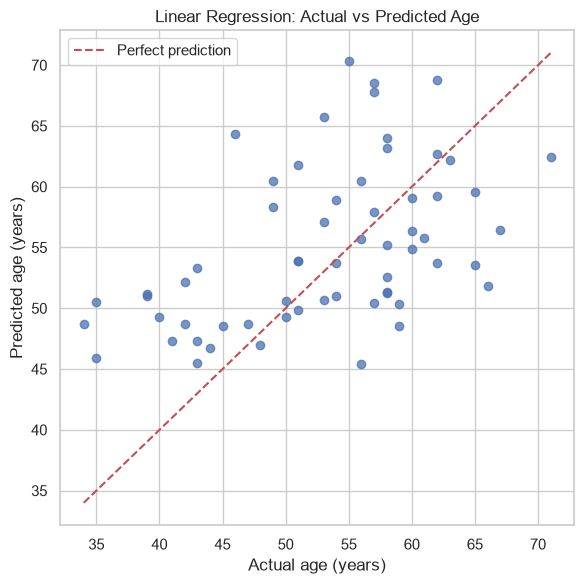

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(yr_test, reg_pred, alpha=0.75)
low = min(yr_test.min(), reg_pred.min())
high = max(yr_test.max(), reg_pred.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")
plt.xlabel("Actual age (years)")
plt.ylabel("Predicted age (years)")
plt.title("Linear Regression: Actual vs Predicted Age")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "regression_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

### Regression interpretation
Points near the diagonal represent more accurate predictions. RMSE is the approximate error scale in years; lower is better. R² closer to 1 indicates more variance explained, around 0 is similar to predicting the mean, and below 0 is worse than the mean baseline. Because this dataset is small and not designed for age prediction, interpret results as a learning exercise only.

## 7. Classification — Logistic Regression

**Target:** `target` (0 = no disease; 1 = disease present).  
The model outputs a class prediction. Accuracy is the overall fraction correct; precision asks how many predicted positives are truly positive; recall asks how many actual positives are found; F1 balances precision and recall.

In [11]:
X_clf = df[all_features]
y_clf = df["target"].astype(int)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=RANDOM_STATE, stratify=y_clf
)

clf_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

clf_model = Pipeline([
    ("preprocessor", clf_preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
clf_model.fit(Xc_train, yc_train)
clf_pred = clf_model.predict(Xc_test)

clf_accuracy = accuracy_score(yc_test, clf_pred)
clf_precision = precision_score(yc_test, clf_pred, zero_division=0)
clf_recall = recall_score(yc_test, clf_pred, zero_division=0)
clf_f1 = f1_score(yc_test, clf_pred, zero_division=0)

print(f"Accuracy:  {clf_accuracy:.3f}")
print(f"Precision: {clf_precision:.3f}")
print(f"Recall:    {clf_recall:.3f}")
print(f"F1 score:  {clf_f1:.3f}")
print("\nClassification report:\n", classification_report(yc_test, clf_pred, zero_division=0))

Accuracy:  0.885
Precision: 0.839
Recall:    0.929
F1 score:  0.881

Classification report:
               precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



True Negatives (TN): 28
False Positives (FP): 5
False Negatives (FN): 2
True Positives (TP): 26


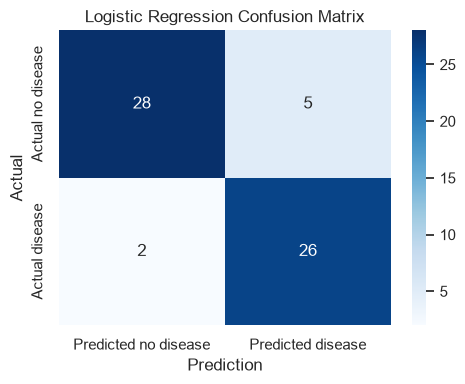

In [12]:
cm = confusion_matrix(yc_test, clf_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP): {tp}")

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted no disease", "Predicted disease"],
            yticklabels=["Actual no disease", "Actual disease"])
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### Confusion matrix and precision–recall trade-off
- **True Positive (TP):** disease is present and the model predicts disease.
- **True Negative (TN):** disease is absent and the model predicts no disease.
- **False Positive (FP):** the model predicts disease when the label is absent.
- **False Negative (FN):** the model predicts no disease when the label is present.

Higher recall reduces false negatives, while higher precision reduces false positives among positive predictions. In a real medical screening context, missed cases can be serious, but false alarms also have costs. The right threshold must be chosen with clinical expertise and validation; this educational model is not a diagnostic tool.

## 8. Clustering — K-Means

K-Means is unsupervised: the disease target is excluded. We impute missing values, one-hot encode category codes, and scale features before computing distances. The Elbow Method plots inertia for K=1–10. Choose K by looking for a bend where additional clusters yield smaller improvements. The silhouette score ranges from -1 to 1; higher generally indicates better separation, but it should be interpreted alongside the plots and domain context.

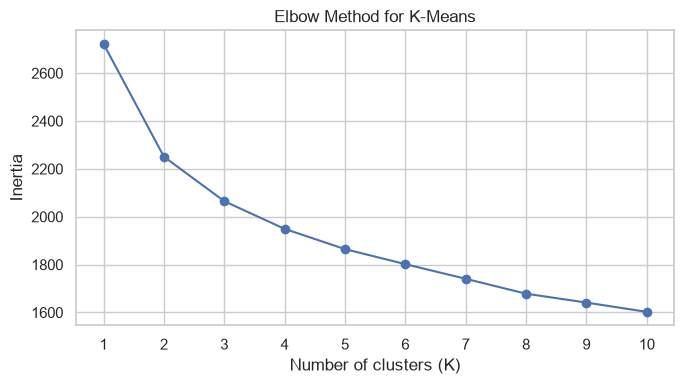

In [13]:
cluster_numeric = numeric_features
cluster_categorical = categorical_features
X_cluster = df[cluster_numeric + cluster_categorical]

cluster_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), cluster_numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cluster_categorical)
])

X_scaled = cluster_preprocessor.fit_transform(X_cluster)
# KMeans works with dense arrays for this small dataset.
if hasattr(X_scaled, "toarray"):
    X_scaled = X_scaled.toarray()

inertias = []
k_values = range(1, 11)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "kmeans_elbow.png", dpi=150, bbox_inches="tight")
plt.show()

### Select K
The elbow is a visual heuristic, not a guaranteed mathematical optimum. Inspect the curve and set `SELECTED_K` below. The default value is 3 as a starting point; change it if the elbow plot supports a different choice. The silhouette score requires at least 2 clusters and fewer clusters than samples.

In [14]:
SELECTED_K = 3  # Update after inspecting the elbow curve if appropriate.

kmeans = KMeans(n_clusters=SELECTED_K, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)
df["cluster"] = cluster_labels

silhouette = silhouette_score(X_scaled, cluster_labels)
print(f"Selected K: {SELECTED_K}")
print(f"Silhouette score: {silhouette:.3f}")
print("\nCluster sizes:")
display(df["cluster"].value_counts().sort_index().rename("count").to_frame())

Selected K: 3
Silhouette score: 0.126

Cluster sizes:


,count
cluster,
0,121
1,103
2,79


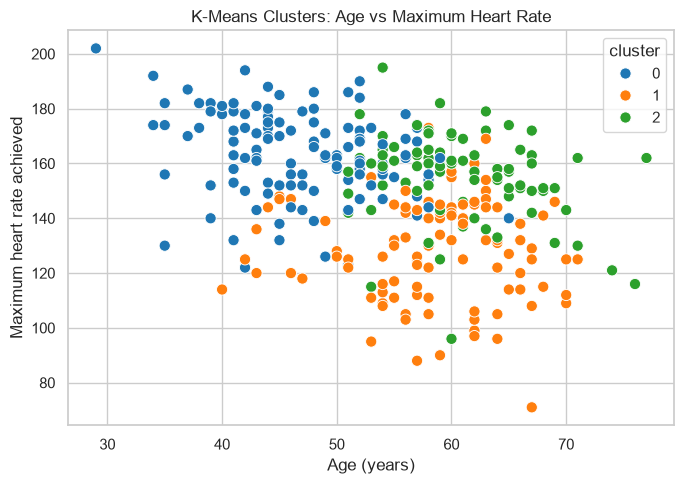

Cluster feature averages (target shown only for post-hoc interpretation, not used for clustering):


,age,trestbps,chol,thalach,oldpeak,target
cluster,,,,,,
0,46.86,123.94,228.96,163.90,0.47,0.21
1,58.32,134.23,248.88,128.77,2.12,0.85
2,60.99,140.24,271.00,154.89,0.50,0.32


In [15]:
# Visualize cluster assignments using two understandable features.
# These are raw features for interpretation; cluster fitting used the scaled encoded matrix.
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="age", y="thalach", hue="cluster", palette="tab10", s=65)
plt.title("K-Means Clusters: Age vs Maximum Heart Rate")
plt.xlabel("Age (years)")
plt.ylabel("Maximum heart rate achieved")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "kmeans_clusters_age_thalach.png", dpi=150, bbox_inches="tight")
plt.show()

cluster_profile = df.groupby("cluster")[["age", "trestbps", "chol", "thalach", "oldpeak", "target"]].mean().round(2)
print("Cluster feature averages (target shown only for post-hoc interpretation, not used for clustering):")
display(cluster_profile)

### Cluster interpretation
Clusters are mathematical groupings based on feature similarity, not confirmed patient types or diagnoses. Use the cluster-size table, scatter plot, and profile averages to describe differences in age, maximum heart rate, blood pressure, cholesterol, and other measurements. The target average is included only after clustering to help inspect composition; it was not used to create clusters. Avoid claiming that a cluster has a clinical meaning without external validation.

## 9. Compare the results

The next cell builds a compact summary table from the actual metric values generated above and saves it to `results/metrics_summary.csv`.

In [16]:
results_table = pd.DataFrame([
    {
        "Model Name": "Linear Regression",
        "Task": "Regression (predict age)",
        "Evaluation Metrics": f"MSE={reg_mse:.3f}; RMSE={reg_rmse:.3f}; R²={reg_r2:.3f}",
        "Interpretation": "Lower MSE/RMSE is better; higher R² is better."
    },
    {
        "Model Name": "Logistic Regression",
        "Task": "Binary classification (disease label)",
        "Evaluation Metrics": f"Accuracy={clf_accuracy:.3f}; Precision={clf_precision:.3f}; Recall={clf_recall:.3f}; F1={clf_f1:.3f}",
        "Interpretation": "Balance correct predictions with missed positives and false alarms."
    },
    {
        "Model Name": "K-Means",
        "Task": "Unsupervised clustering",
        "Evaluation Metrics": f"K={SELECTED_K}; Silhouette={silhouette:.3f}",
        "Interpretation": "Higher silhouette generally suggests more separated clusters."
    }
])
display(results_table)
results_table.to_csv(RESULTS_DIR / "metrics_summary.csv", index=False)

,Model Name,Task,Evaluation Metrics,Interpretation
0,Linear Regression,Regression (predict age),MSE=65.254; RMSE=8.078; R²=0.117,Lower MSE/RMSE is better; higher R² is better.
1,Logistic Regression,Binary classification (disease label),Accuracy=0.885; Precision=0.839; Recall=0.929;...,Balance correct predictions with missed positi...
2,K-Means,Unsupervised clustering,K=3; Silhouette=0.126,Higher silhouette generally suggests more sepa...


### Strengths and weaknesses
- **Linear Regression:** simple and interpretable; may miss nonlinear relationships and is not a natural primary task for this dataset.
- **Logistic Regression:** efficient baseline with interpretable probabilities; may underfit nonlinear patterns and is sensitive to data quality and class balance.
- **K-Means:** discovers groups without labels; requires choosing K and can be affected by scaling, initialization, and the distance metric.

There is no single metric that makes regression, classification, and clustering directly comparable. Identify the best method within each task using the task-appropriate metrics. For this project, classification is the most aligned with the dataset's intended purpose, but model quality must be judged from the executed results and should not be generalized to clinical use.

## 9b. Supporting analysis for the report

This section prints the numbers quoted in the written report: feature correlations with the target, outlier counts, cluster profiles, inertia drops for the elbow curve, and silhouette scores for several values of K. It must run after the clustering cells above because it uses `df`, `X_scaled`, and the `cluster` column.

In [17]:
# Correlations of each feature with the disease target (EDA section of the report)
d = df.drop(columns="cluster", errors="ignore").assign(target=df["target"].astype(int))

print("CORRELATION WITH TARGET")
corr = d.corr(numeric_only=True)["target"].drop("target")
print(corr.reindex(corr.abs().sort_values(ascending=False).index).round(2))

# Outlier counts using the 1.5 x IQR rule (boxplot rule)
print("\nOUTLIERS (IQR rule)")
for col in ["age", "trestbps", "chol", "thalach", "oldpeak"]:
    q1, q3 = d[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((d[col] < q1 - 1.5 * iqr) | (d[col] > q3 + 1.5 * iqr)).sum()
    print(col, n)

# Cluster profiles (target shown only for interpretation; it was not used for clustering)
print("\nCLUSTER PROFILES")
profile = df.assign(target=df["target"].astype(int)).groupby("cluster")[
    ["age", "thalach", "trestbps", "chol", "oldpeak", "target"]
].mean().round(2)
print(profile)

# Inertia for K = 1..10 and the percentage drop at each step (elbow discussion)
print("\nINERTIA DROPS")
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
    inertias.append(km.inertia_)

for k in range(2, 11):
    drop = (inertias[k - 2] - inertias[k - 1]) / inertias[k - 2] * 100
    print(f"K={k}: inertia={inertias[k-1]:.1f}, drop from K={k-1}: {drop:.1f}%")

# Silhouette score for K = 2..6 (justification of the chosen K)
print("\nSILHOUETTE BY K")
for k in range(2, 7):
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X_scaled)
    print(k, round(silhouette_score(X_scaled, labels), 3))

CORRELATION WITH TARGET
thal        0.53
ca          0.46
exang       0.43
oldpeak     0.42
thalach    -0.42
cp          0.41
slope       0.34
sex         0.28
age         0.22
restecg     0.17
trestbps    0.15
chol        0.09
fbs         0.03
Name: target, dtype: float64

OUTLIERS (IQR rule)
age 0
trestbps 9
chol 5
thalach 1
oldpeak 5

CLUSTER PROFILES
           age  thalach  trestbps    chol  oldpeak  target
cluster                                                   
0        46.86   163.90    123.94  228.96     0.47    0.21
1        58.32   128.77    134.23  248.88     2.12    0.85
2        60.99   154.89    140.24  271.00     0.50    0.32

INERTIA DROPS
K=2: inertia=2250.8, drop from K=1: 17.3%
K=3: inertia=2064.8, drop from K=2: 8.3%
K=4: inertia=1949.2, drop from K=3: 5.6%
K=5: inertia=1864.6, drop from K=4: 4.3%
K=6: inertia=1801.8, drop from K=5: 3.4%
K=7: inertia=1740.5, drop from K=6: 3.4%
K=8: inertia=1678.3, drop from K=7: 3.6%
K=9: inertia=1641.2, drop from K=8: 2.2%
K=10

## 10. Export final outputs

This cell saves the cleaned data and summary metrics. Figures are saved in `results/` throughout the notebook. If you need a report with the measured metrics, copy the values from the comparison table into the report template after running all cells.

In [18]:
# Save the cleaned dataset, including derived target and cluster assignment.
df.to_csv(DATA_DIR / "heart_disease_cleaned.csv", index=False)
print("Saved:")
print("-", DATA_DIR / "heart_disease_cleaned.csv")
print("-", RESULTS_DIR / "metrics_summary.csv")
print("Plots saved in:", RESULTS_DIR.resolve())

PermissionError: [Errno 13] Permission denied: '..\\data\\heart_disease_cleaned.csv'

## References
1. Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. UCI Heart Disease Dataset. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4C
2. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
3. Scikit-learn documentation: https://scikit-learn.org/stable/

**Submission checklist:** run all cells, inspect plots, update the final report with measured metrics, add your name/course details if required, save the notebook, upload it to Google Colab, and place the shareable Colab URL in the PDF.